In [ ]:
import pandas as pd
import os

print("CityPulse Air Watch")
print("Let's inspect our AQI dataset!")

print(os.listdir('/content'))


CityPulse Air Watch
Let's inspect our AQI dataset!
['.config', 'sample_data']


In [ ]:
import os

files = [
    f for f in os.listdir('/content')
    if os.path.isfile(os.path.join('/content', f))
]

print("Total files uploaded:", len(files))

for i, file in enumerate(files, 1):
    size_mb = os.path.getsize(os.path.join('/content', file)) / (1024 * 1024)
    print(f"{i}. {file} ({size_mb:.2f} MB)")

Total files uploaded: 8
1. Advance_Search_1792672262632.xlsx (0.38 MB)
2. Advance_Search_1792673076381.xlsx (0.42 MB)
3. Advance_Search_1792671763347.xlsx (0.37 MB)
4. Advance_Search_1792673310690.xlsx (0.37 MB)
5. Advance_Search_1792673241762.xlsx (0.46 MB)
6. Advance_Search_1792672943405.xlsx (0.33 MB)
7. Advance_Search_1792672709872.xlsx (0.44 MB)
8. Advance_Search_1792673175387.xlsx (0.53 MB)


In [ ]:
import pandas as pd
import os
import glob

files = glob.glob('/content/*.xlsx')

for file in sorted(files):
    print("\n" + "=" * 70)
    print("FILE:", os.path.basename(file))

    try:
        excel = pd.ExcelFile(file)
        print("Sheets:", excel.sheet_names)

        for sheet in excel.sheet_names:
            df = pd.read_excel(file, sheet_name=sheet)

            print(f"\nSheet: {sheet}")
            print("Rows and columns:", df.shape)
            print("Column names:")
            print(df.columns.tolist())

            print("\nFirst 3 rows:")
            print(df.head(3).to_string(index=False))

    except Exception as e:
        print("Could not read file:", e)


FILE: Advance_Search_1792671763347.xlsx
Sheets: ['CPCB Ambient AQ']

Sheet: CPCB Ambient AQ
Rows and columns: (8746, 10)
Column names:
['CENTRAL POLLUTION CONTROL BOARD', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9']

First 3 rows:
CENTRAL POLLUTION CONTROL BOARD Unnamed: 1  Unnamed: 2 Unnamed: 3 Unnamed: 4     Unnamed: 5 Unnamed: 6 Unnamed: 7 Unnamed: 8 Unnamed: 9
 CONTINUOUS AMBIENT AIR QUALITY        NaN         NaN        NaN        NaN            NaN        NaN        NaN        NaN        NaN
               Date: 22-10-2026        NaN         NaN        NaN        NaN Time: 17:52:06        NaN        NaN        NaN        NaN
                          State        NaN Maharashtra        NaN        NaN            NaN        NaN        NaN        NaN        NaN

FILE: Advance_Search_1792672262632.xlsx
Sheets: ['CPCB Ambient AQ']

Sheet: CPCB Ambient AQ
Rows and columns: (7066, 10)
Column names:
['CENTR

In [ ]:
import pandas as pd
import glob
import os

files = sorted(glob.glob('/content/*.xlsx'))

for file in files:
    print("\n" + "=" * 80)
    print("FILE:", os.path.basename(file))

    raw = pd.read_excel(file, header=None)

    # Show the first 25 rows without assuming a header
    print(raw.head(25).dropna(how='all').to_string(
        index=True, header=False
    ))



FILE: Advance_Search_1792671763347.xlsx
0   CENTRAL POLLUTION CONTROL BOARD               NaN                                  NaN   NaN  NaN             NaN  NaN  NaN  NaN    NaN
1    CONTINUOUS AMBIENT AIR QUALITY               NaN                                  NaN   NaN  NaN             NaN  NaN  NaN  NaN    NaN
2                  Date: 22-10-2026               NaN                                  NaN   NaN  NaN  Time: 17:52:06  NaN  NaN  NaN    NaN
3                             State               NaN                          Maharashtra   NaN  NaN             NaN  NaN  NaN  NaN    NaN
4                              City               NaN                               Mumbai   NaN  NaN             NaN  NaN  NaN  NaN    NaN
5                           Station               NaN  Bandra Kurla Complex, Mumbai - IITM   NaN  NaN             NaN  NaN  NaN  NaN    NaN
6                         Parameter               NaN   NO,PM10,PM2.5,NO2,SO2,CO,Ozone,NH3   NaN  NaN             NaN  

In [ ]:
import pandas as pd
import glob
import os

# 1. Find all uploaded Excel files
files = sorted(glob.glob('/content/*.xlsx'))

if len(files) == 0:
    raise ValueError("No Excel files found. Please upload your CPCB files.")

print("Excel files found:", len(files))

all_data = []
reports = []

# 2. Read and process each Excel file
for file in files:
    print("Processing:", os.path.basename(file))

    # Read report metadata
    raw = pd.read_excel(file, header=None)

    station = raw.iloc[5, 2]
    period_start = raw.iloc[8, 2]
    period_end = raw.iloc[9, 2]

    # Actual column headers are on Excel row 11
    df = pd.read_excel(file, header=10)

    # Remove completely empty rows and columns
    df = df.dropna(how='all').dropna(axis=1, how='all')
    df.columns = df.columns.astype(str).str.strip()

    # Check that expected date columns exist
    required_dates = ['From Date', 'To Date']
    missing_dates = [c for c in required_dates if c not in df.columns]

    if missing_dates:
        print("Skipping file because date columns are missing:", file)
        continue

    # Convert dates into proper datetime format
    for col in required_dates:
        df[col] = pd.to_datetime(
            df[col], dayfirst=True, errors='coerce'
        )

    # Convert pollutant measurements into numbers
    pollutant_cols = [
        c for c in df.columns
        if c not in ['From Date', 'To Date']
    ]

    for col in pollutant_cols:
        df[col] = pd.to_numeric(df[col], errors='coerce')

    # Add station and source information
    df['Station'] = station
    df['Source_File'] = os.path.basename(file)

    all_data.append(df)

    # Create a summary for this file
    reports.append({
        'File': os.path.basename(file),
        'Station': station,
        'Period_Start': period_start,
        'Period_End': period_end,
        'Rows': len(df),
        'Missing_From_Date': df['From Date'].isna().sum(),
        'Missing_To_Date': df['To Date'].isna().sum(),
        'Duplicate_Timestamps': df.duplicated(
            subset=['From Date', 'To Date']
        ).sum()
    })

# 3. Combine all files
if not all_data:
    raise ValueError(
        "No files were processed successfully. Check the Excel headers."
    )

combined = pd.concat(all_data, ignore_index=True)
report = pd.DataFrame(reports)

# 4. Display file summary
print("\n===== FILE SUMMARY =====")
display(report)

# 5. Check missing values in each file
print("\n===== MISSING VALUES BY FILE (%) =====")

for file_name, group in combined.groupby('Source_File'):
    print("\nFile:", file_name)

    measurements = group.drop(
        columns=['Station', 'Source_File', 'From Date', 'To Date'],
        errors='ignore'
    )

    missing_percent = (
        measurements.isna().mean().mul(100).round(1)
    )

    display(missing_percent.to_frame('Missing_Percent'))

# 6. Overall dataset summary
print("\n===== COMBINED DATASET =====")
print("Total rows:", len(combined))
print("Total columns:", len(combined.columns))
print("\nStations:")
print(combined['Station'].value_counts(dropna=False))

print("\nFirst 5 rows:")
display(combined.head())

# 7. Overall missing-value summary
print("\n===== OVERALL MISSING VALUES (%) =====")
display(
    combined.isna().mean().mul(100).round(1)
    .to_frame('Missing_Percent')
)

# 8. Save the combined data and reports
combined.to_csv(
    '/content/mumbai_pollution_combined.csv', index=False
)
report.to_csv(
    '/content/cpcb_file_summary.csv', index=False
)

print("\nSaved combined data and file summary to Colab.")

Excel files found: 8
Processing: Advance_Search_1792671763347.xlsx
Processing: Advance_Search_1792672262632.xlsx
Processing: Advance_Search_1792672709872.xlsx
Processing: Advance_Search_1792672943405.xlsx
Processing: Advance_Search_1792673076381.xlsx
Processing: Advance_Search_1792673175387.xlsx
Processing: Advance_Search_1792673241762.xlsx
Processing: Advance_Search_1792673310690.xlsx

===== FILE SUMMARY =====


,File,Station,Period_Start,Period_End,Rows,Missing_From_Date,Missing_To_Date,Duplicate_Timestamps
0,Advance_Search_1792671763347.xlsx,"Bandra Kurla Complex, Mumbai - IITM",2025-01-01 00:00:00,2025-12-31 00:00:00,8736,0,0,0
1,Advance_Search_1792672262632.xlsx,"Bandra Kurla Complex, Mumbai - IITM",2026-01-01 00:00:00,2026-10-22 00:00:00,7056,0,0,0
2,Advance_Search_1792672709872.xlsx,"Borivali East, Mumbai - MPCB",2025-01-01 00:00:00,2025-12-31 00:00:00,8736,0,0,0
3,Advance_Search_1792672943405.xlsx,"Borivali East, Mumbai - MPCB",2026-01-01 00:00:00,2026-10-22 00:00:00,7056,0,0,0
4,Advance_Search_1792673076381.xlsx,"Chembur, Mumbai - MPCB",2026-01-01 00:00:00,2026-10-22 00:00:00,7056,0,0,0
5,Advance_Search_1792673175387.xlsx,"Chembur, Mumbai - MPCB",2025-01-01 00:00:00,2025-12-31 00:00:00,8736,0,0,0
6,Advance_Search_1792673241762.xlsx,"Siddharth Nagar-Worli, Mumbai - IITM",2025-01-01 00:00:00,2025-12-31 00:00:00,8736,0,0,0
7,Advance_Search_1792673310690.xlsx,"Siddharth Nagar-Worli, Mumbai - IITM",2026-01-01 00:00:00,2026-10-22 00:00:00,7056,0,0,0



===== MISSING VALUES BY FILE (%) =====

File: Advance_Search_1792671763347.xlsx


,Missing_Percent
PM2.5,47.6
PM10,48.0
NO,48.7
NO2,49.5
NH3,48.7
SO2,49.3
CO,43.4



File: Advance_Search_1792672262632.xlsx


...


===== COMBINED DATASET =====
Total rows: 63168
Total columns: 11

Stations:
Station
Bandra Kurla Complex, Mumbai - IITM     15792
Borivali East, Mumbai - MPCB            15792
Chembur, Mumbai - MPCB                  15792
Siddharth Nagar-Worli, Mumbai - IITM    15792
Name: count, dtype: int64

First 5 rows:


,From Date,To Date,PM2.5,PM10,NO,NO2,NH3,SO2,CO,Station,Source_File
0,2025-01-01 00:00:00,2025-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
1,2025-01-01 01:00:00,2025-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
2,2025-01-01 02:00:00,2025-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
3,2025-01-01 03:00:00,2025-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
4,2025-01-01 04:00:00,2025-01-01 05:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx



===== OVERALL MISSING VALUES (%) =====


,Missing_Percent
From Date,0.0
To Date,0.0
PM2.5,20.7
PM10,21.4
NO,19.7
NO2,23.7
NH3,20.2
SO2,42.9
CO,18.9
Station,0.0



Saved combined data and file summary to Colab.


In [ ]:
# STEP 2: Check dataset quality

print("Dataset shape (rows, columns):", combined.shape)

print("\n1. Missing values in each column:")
print(combined.isna().sum())

print("\n2. Duplicate complete rows:")
print(combined.duplicated().sum())

print("\n3. Duplicate timestamps within each station:")
print(
    combined.duplicated(
        subset=['Station', 'From Date', 'To Date']
    ).sum()
)

print("\n4. Date range:")
print("Earliest:", combined['From Date'].min())
print("Latest:", combined['From Date'].max())

print("\n5. Records per station:")
print(combined['Station'].value_counts())

print("\n6. Sample records:")
display(combined.head(10))

Dataset shape (rows, columns): (63168, 11)

1. Missing values in each column:
From Date          0
To Date            0
PM2.5          13090
PM10           13488
NO             12449
NO2            14973
NH3            12762
SO2            27116
CO             11933
Station            0
Source_File        0
dtype: int64

2. Duplicate complete rows:
0

3. Duplicate timestamps within each station:
0

4. Date range:
Earliest: 2025-01-01 00:00:00
Latest: 2026-10-21 23:00:00

5. Records per station:
Station
Bandra Kurla Complex, Mumbai - IITM     15792
Borivali East, Mumbai - MPCB            15792
Chembur, Mumbai - MPCB                  15792
Siddharth Nagar-Worli, Mumbai - IITM    15792
Name: count, dtype: int64

6. Sample records:


,From Date,To Date,PM2.5,PM10,NO,NO2,NH3,SO2,CO,Station,Source_File
0,2025-01-01 00:00:00,2025-01-01 01:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
1,2025-01-01 01:00:00,2025-01-01 02:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
2,2025-01-01 02:00:00,2025-01-01 03:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
3,2025-01-01 03:00:00,2025-01-01 04:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
4,2025-01-01 04:00:00,2025-01-01 05:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
5,2025-01-01 05:00:00,2025-01-01 06:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
6,2025-01-01 06:00:00,2025-01-01 07:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
7,2025-01-01 07:00:00,2025-01-01 08:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
8,2025-01-01 08:00:00,2025-01-01 09:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx
9,2025-01-01 09:00:00,2025-01-01 10:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Bandra Kurla Complex, Mumbai - IITM",Advance_Search_1792671763347.xlsx


In [ ]:
# STEP 3: Investigate missing values by station and year

pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NH3', 'SO2', 'CO'
]

# Create a year column
combined['Year'] = combined['From Date'].dt.year

print("===== MISSING VALUES BY STATION (%) =====")

station_missing = (
    combined.groupby('Station')[pollutants]
    .apply(lambda group: group.isna().mean() * 100)
    .round(1)
)

display(station_missing)

print("\n===== MISSING VALUES BY YEAR (%) =====")

year_missing = (
    combined.groupby('Year')[pollutants]
    .apply(lambda group: group.isna().mean() * 100)
    .round(1)
)

display(year_missing)

print("\n===== RECORDS WITH ALL POLLUTANTS MISSING =====")

all_missing = combined[pollutants].isna().all(axis=1)

print("Rows with every pollutant missing:", all_missing.sum())
print(
    "Percentage of all records:",
    round(all_missing.mean() * 100, 2), "%"
)

print("\n===== ALL-POLLUTANT MISSING ROWS BY STATION =====")

display(
    combined.assign(All_Pollutants_Missing=all_missing)
    .groupby('Station')['All_Pollutants_Missing']
    .agg(['sum', 'count'])
    .rename(columns={
        'sum': 'All_Missing_Rows',
        'count': 'Total_Rows'
    })
)

===== MISSING VALUES BY STATION (%) =====


,PM2.5,PM10,NO,NO2,NH3,SO2,CO
Station,,,,,,,
"Bandra Kurla Complex, Mumbai - IITM",36.7,35.7,36.7,39.1,37.1,37.0,33.1
"Borivali East, Mumbai - MPCB",25.7,33.7,23.6,35.1,24.5,28.3,27.4
"Chembur, Mumbai - MPCB",5.9,5.8,6.0,5.0,6.1,6.4,5.2
"Siddharth Nagar-Worli, Mumbai - IITM",14.5,10.2,12.5,15.6,13.1,100.0,9.9



===== MISSING VALUES BY YEAR (%) =====


,PM2.5,PM10,NO,NO2,NH3,SO2,CO
Year,,,,,,,
2025,22.8,24.5,21.8,23.5,22.2,45.3,20.7
2026,18.1,17.5,17.1,23.9,17.8,39.9,16.7



===== RECORDS WITH ALL POLLUTANTS MISSING =====
Rows with every pollutant missing: 9981
Percentage of all records: 15.8 %

===== ALL-POLLUTANT MISSING ROWS BY STATION =====


,All_Missing_Rows,Total_Rows
Station,,
"Bandra Kurla Complex, Mumbai - IITM",4966,15792
"Borivali East, Mumbai - MPCB",3335,15792
"Chembur, Mumbai - MPCB",664,15792
"Siddharth Nagar-Worli, Mumbai - IITM",1016,15792


In [ ]:
# STEP 4: Missing values by original file

pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NH3', 'SO2', 'CO'
]

file_missing = (
    combined.groupby(['Station', 'Source_File'])[pollutants]
    .agg(lambda col: round(col.isna().mean() * 100, 1))
)

display(file_missing)

print("\n===== FILES WITH 100% MISSING SO2 =====")
so2_missing = (
    combined.groupby('Source_File')['SO2']
    .apply(lambda col: col.isna().mean() * 100)
)

display(so2_missing[so2_missing == 100].to_frame(
    'SO2_Missing_Percent'
))

PM2.5  \
Station                              Source_File                                
Bandra Kurla Complex, Mumbai - IITM  Advance_Search_1792671763347.xlsx   47.6   
                                     Advance_Search_1792672262632.xlsx   23.3   
Borivali East, Mumbai - MPCB         Advance_Search_1792672709872.xlsx   22.1   
                                     Advance_Search_1792672943405.xlsx   30.2   
Chembur, Mumbai - MPCB               Advance_Search_1792673076381.xlsx    6.1   
                                     Advance_Search_1792673175387.xlsx    5.7   
Siddharth Nagar-Worli, Mumbai - IITM Advance_Search_1792673241762.xlsx   16.0   
                                     Advance_Search_1792673310690.xlsx   12.7   

                                                                        PM10  \
Station                              Source_File                               
Bandra Kurla Complex, Mumbai - IITM  Advance_Search_1792671763347.xlsx  48.0   
                                     Advance_Search_1792672262632.xlsx  20.6   
Borivali East, Mumbai - MPCB         Advance_Search_1792672709872.xlsx  34.0   
                                     Advance_Search_1792672943405.xlsx  33.4   
Chembur, Mumbai - MPCB               Advance_Search_1792673076381.xlsx   5.9   
                                     Advance_Search_1792673175387.xlsx   5.7   
Siddharth Nagar-Worli, Mumbai - IITM Advance_Search_1792673241762.xlsx  10.3   
                                     Advance_Search_1792673310690.xlsx  10.0   

                                                                          NO  \
Station                              Source_File                               
Bandra Kurla Complex, Mumbai - IITM  Advance_Search_1792671763347.xlsx  48.7   
                                     Advance_Search_1792672262632.xlsx  21.9   
Borivali East, Mumbai - MPCB         Advance_Search_1792672709872.xlsx  19.3   
                                     Advance_Search_1792672943405.xlsx  29.0   
Chembur, Mumbai - MPCB               Advance_Search_1792673076381.xlsx   5.8   
                                     Advance_Search_1792673175387.xlsx   6.1   
Siddharth Nagar-Worli, Mumbai - IITM Advance_Search_1792673241762.xlsx  13.2   
                                     Advance_Search_1792673310690.xlsx  11.7   

                                                                         NO2  \
Station                              Source_File                               
Bandra Kurla Complex, Mumbai - IITM  Advance_Search_1792671763347.xlsx  49.5   
                                     Advance_Search_1792672262632.xlsx  26.2   
Borivali East, Mumbai - MPCB         Advance_Search_1792672709872.xlsx  22.8   
                                     Advance_Search_1792672943405.xlsx  50.4   
Chembur, Mumbai - MPCB               Advance_Search_1792673076381.xlsx   5.8   
                                     Advance_Search_1792673175387.xlsx   4.3   
Siddharth Nagar-Worli, Mumbai - IITM Advance_Search_1792673241762.xlsx  17.6   
                                     Advance_Search_1792673310690.xlsx  13.2   

                                                                         NH3  \
Station                              Source_File                               
Bandra Kurla Complex, Mumbai - IITM  Advance_Search_1792671763347.xlsx  48.7   
                                     Advance_Search_1792672262632.xlsx  22.7   
Borivali East, Mumbai - MPCB         Advance_Search_1792672709872.xlsx  20.9   
                                     Advance_Search_1792672943405.xlsx  29.0   
Chembur, Mumbai - MPCB               Advance_Search_1792673076381.xlsx   6.3   
                                     Advance_Search_1792673175387.xlsx   5.9   
Siddharth Nagar-Worli, Mumbai - IITM Advance_Search_1792673241762.xlsx  13.2   
                                     Advance_Search_1792673310690.xlsx  13.1   

                                                         


===== FILES WITH 100% MISSING SO2 =====


,SO2_Missing_Percent
Source_File,
Advance_Search_1792673241762.xlsx,100.0
Advance_Search_1792673310690.xlsx,100.0


In [ ]:
# STEP 5: Create an analysis-ready copy

pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NH3', 'SO2', 'CO'
]

# Keep the original combined dataset unchanged
eda_data = combined.copy()

# Identify rows with no pollutant measurements at all
all_missing = eda_data[pollutants].isna().all(axis=1)

print("Rows before filtering:", len(eda_data))
print("Rows with all pollutants missing:", all_missing.sum())

# Exclude only completely empty measurement rows
eda_data = eda_data.loc[~all_missing].copy()

print("Rows retained for EDA:", len(eda_data))
print("Rows removed from analysis copy:", all_missing.sum())

print("\nRemaining missing values:")
display(eda_data[pollutants].isna().sum())

# Save the analysis-ready copy
eda_data.to_csv(
    '/content/mumbai_pollution_eda_ready.csv',
    index=False
)

print("\nSaved: mumbai_pollution_eda_ready.csv")

Rows before filtering: 63168
Rows with all pollutants missing: 9981
Rows retained for EDA: 53187
Rows removed from analysis copy: 9981

Remaining missing values:


,0
PM2.5,3109
PM10,3507
NO,2468
NO2,4992
NH3,2781
SO2,17135
CO,1952



Saved: mumbai_pollution_eda_ready.csv


In [ ]:
 # STEP 6: Descriptive statistics for each station

pollutants = [
    'PM2.5', 'PM10', 'NO', 'NO2', 'NH3', 'SO2', 'CO'
]

# Calculate statistics station by station
station_stats = eda_data.groupby('Station')[pollutants].agg(
    ['mean', 'median', 'min', 'max', 'count']
).round(2)

display(station_stats)

# Save the results for your project
station_stats.to_csv('/content/station_pollution_statistics.csv')

print("Saved: station_pollution_statistics.csv")

PM2.5                              \
                                       mean median   min     max  count   
Station                                                                   
Bandra Kurla Complex, Mumbai - IITM   33.50  23.64  0.05  555.79   9991   
Borivali East, Mumbai - MPCB          23.61  19.36  0.67  160.40  11729   
Chembur, Mumbai - MPCB                30.21  22.71  0.04  771.39  14862   
Siddharth Nagar-Worli, Mumbai - IITM  29.30  18.50  0.07  357.79  13496   

                                        PM10                              ...  \
                                        mean median   min     max  count  ...   
Station                                                                   ...   
Bandra Kurla Complex, Mumbai - IITM   101.06  83.64  0.06  699.41  10149  ...   
Borivali East, Mumbai - MPCB           62.76  53.55  1.75  615.00  10464  ...   
Chembur, Mumbai - MPCB                 75.92  62.44  3.56  469.68  14878  ...   
Siddharth Nagar-Worli, Mumbai - IITM   79.81  64.96  0.68  406.72  14189  ...   

                                        SO2                                CO  \
                                       mean median   min     max  count  mean   
Station                                                                         
Bandra Kurla Complex, Mumbai - IITM    3.97   2.90  0.00   85.61   9953  0.58   
Borivali East, Mumbai - MPCB          11.86  12.10  0.44   53.49  11316  0.19   
Chembur, Mumbai - MPCB                 6.97   3.59  0.00  192.19  14783  0.68   
Siddharth Nagar-Worli, Mumbai - IITM    NaN    NaN   NaN     NaN      0  0.71   

                                                               
                                     median  min   max  count  
Station                                                        
Bandra Kurla Complex, Mumbai - IITM    0.50  0.0  5.43  10565  
Borivali East, Mumbai - MPCB           0.17  0.0  0.79  11468  
Chembur, Mumbai - MPCB                 0.64  0.0  5.14  14968  
Siddharth Nagar-Worli, Mumbai - IITM   0.67  0.0  4.97  14234  

[4 rows x 35 columns]

Saved: station_pollution_statistics.csv


                                      PM2.5    PM10
Station                                            
Bandra Kurla Complex, Mumbai - IITM   33.50  101.06
Borivali East, Mumbai - MPCB          23.61   62.76
Chembur, Mumbai - MPCB                30.21   75.92
Siddharth Nagar-Worli, Mumbai - IITM  29.30   79.81


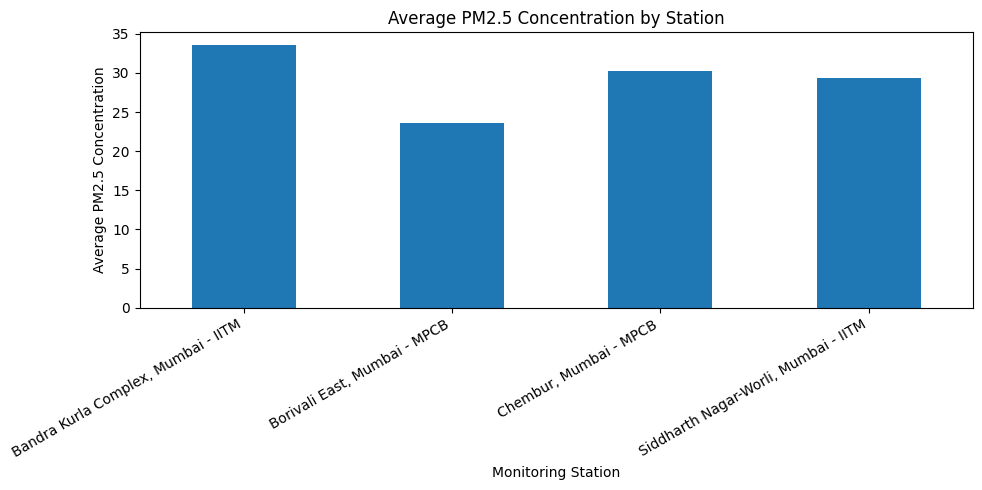

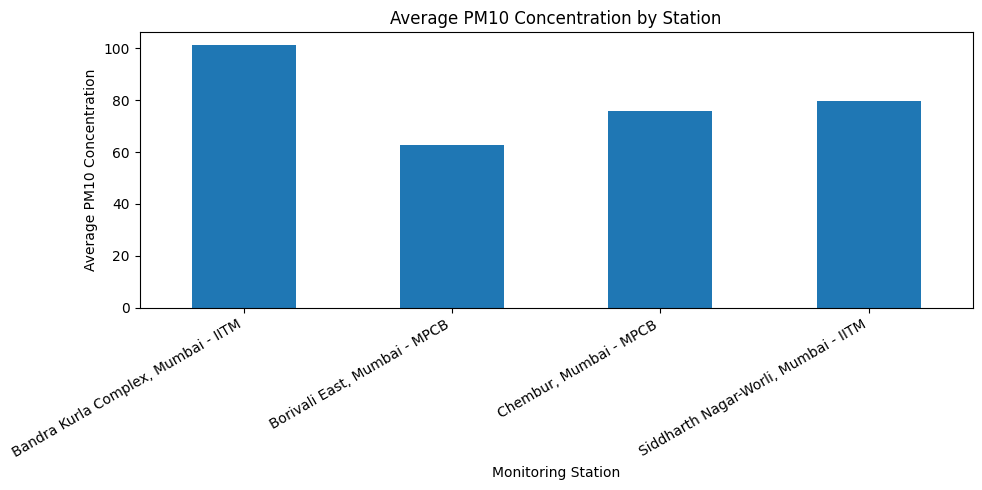

Success! The station averages have been saved.


In [ ]:
import matplotlib.pyplot as plt

# Calculate average pollutant concentrations for each station
station_means = eda_data.groupby("Station")[["PM2.5", "PM10"]].mean()

# Display the average values
print(station_means.round(2))

# Graph 1: Average PM2.5
plt.figure(figsize=(10, 5))
station_means["PM2.5"].plot(kind="bar")
plt.title("Average PM2.5 Concentration by Station")
plt.xlabel("Monitoring Station")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Graph 2: Average PM10
plt.figure(figsize=(10, 5))
station_means["PM10"].plot(kind="bar")
plt.title("Average PM10 Concentration by Station")
plt.xlabel("Monitoring Station")
plt.ylabel("Average PM10 Concentration")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Save the results as a CSV file
station_means.to_csv("/content/station_mean_pm25_pm10.csv")

print("Success! The station averages have been saved.")

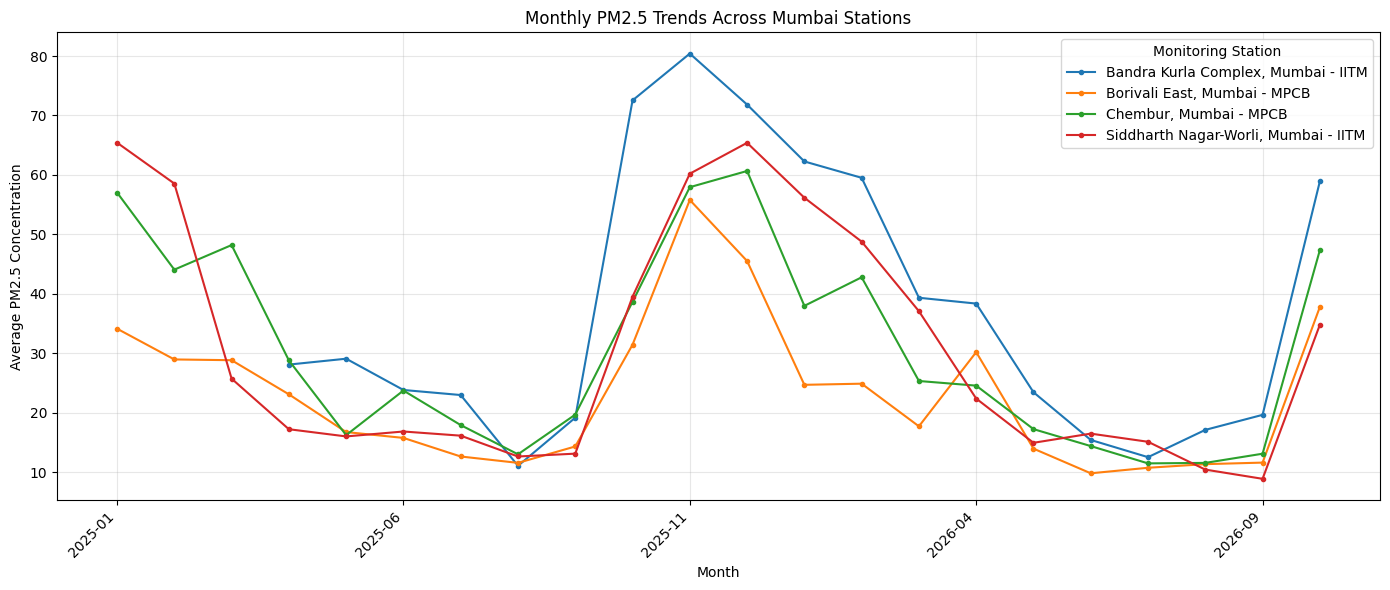

Monthly PM2.5 trends saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert dates into datetime format
eda_data["From Date"] = pd.to_datetime(
    eda_data["From Date"], errors="coerce"
)

# Extract month
eda_data["Month"] = (
    eda_data["From Date"].dt.to_period("M").astype(str)
)

# Calculate monthly average PM2.5 by station
monthly_pm25 = eda_data.pivot_table(
    index="Month",
    columns="Station",
    values="PM2.5",
    aggfunc="mean"
)

# Plot monthly trends
monthly_pm25.plot(figsize=(14, 6), marker=".")
plt.title("Monthly PM2.5 Trends Across Mumbai Stations")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Monitoring Station")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Save the monthly data
monthly_pm25.to_csv("/content/monthly_pm25_trends.csv")

print("Monthly PM2.5 trends saved successfully!")


Station  Bandra Kurla Complex, Mumbai - IITM  Borivali East, Mumbai - MPCB  Chembur, Mumbai - MPCB  Siddharth Nagar-Worli, Mumbai - IITM
Month                                                                                                                                   
2025-01                                  NaN                         34.12                   57.03                                 65.42
2025-02                                  NaN                         28.94                   44.05                                 58.54
2025-03                                  NaN                         28.81                   48.19                                 25.71
2025-04                                28.08                         23.07                   28.78                                 17.20
2025-05                                29.07                         16.72                   16.21                                 15.99
2025-06                                23

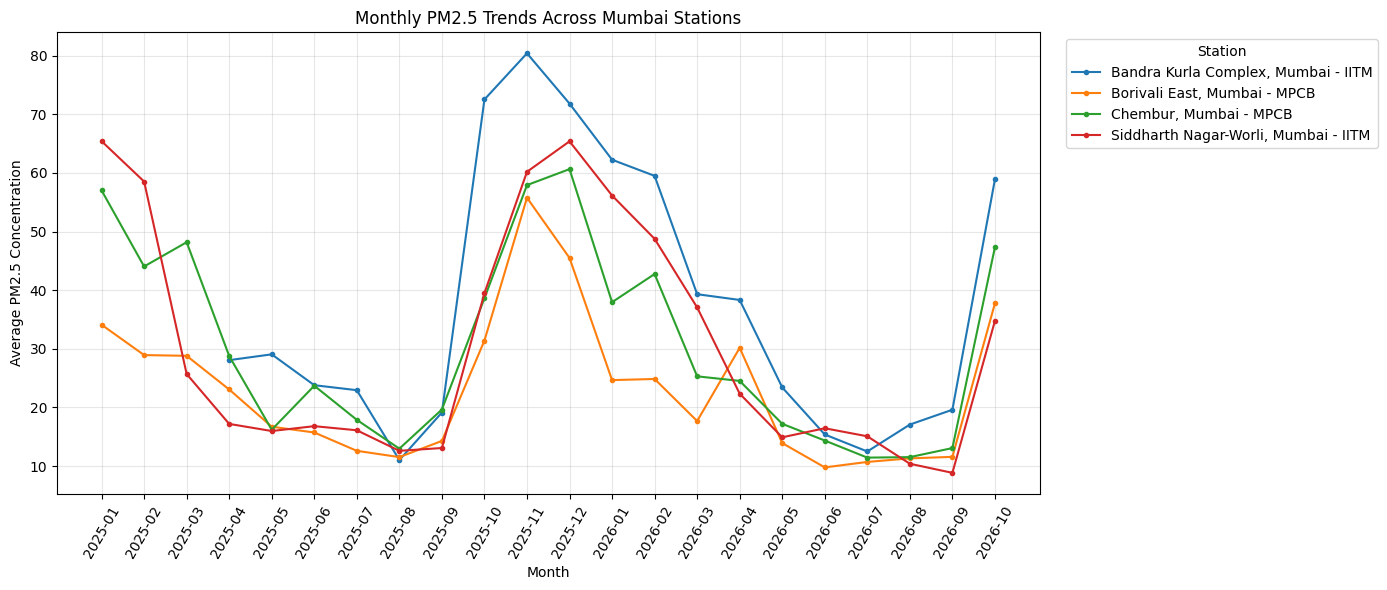

Monthly trend data saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Prepare dates
eda_data["From Date"] = pd.to_datetime(
    eda_data["From Date"], errors="coerce"
)

eda_data["Month"] = eda_data["From Date"].dt.to_period("M")

# Calculate monthly average PM2.5 for every station
monthly_pm25 = (
    eda_data.groupby(["Month", "Station"])["PM2.5"]
    .mean()
    .unstack("Station")
)

# Show the data
print(monthly_pm25.round(2).to_string())

# Draw a separate line for every station
fig, ax = plt.subplots(figsize=(14, 6))

for station in monthly_pm25.columns:
    ax.plot(
        monthly_pm25.index.astype(str),
        monthly_pm25[station],
        marker="o",
        markersize=3,
        label=station
    )

ax.set_title("Monthly PM2.5 Trends Across Mumbai Stations")
ax.set_xlabel("Month")
ax.set_ylabel("Average PM2.5 Concentration")
ax.tick_params(axis="x", rotation=60)
ax.legend(title="Station", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

monthly_pm25.to_csv("/content/monthly_pm25_trends.csv")

print("Monthly trend data saved successfully!")

Station  Bandra Kurla Complex, Mumbai - IITM  Borivali East, Mumbai - MPCB  Chembur, Mumbai - MPCB  Siddharth Nagar-Worli, Mumbai - IITM
Month                                                                                                                                   
2025-01                                  NaN                         34.12                   57.03                                 65.42
2025-02                                  NaN                         28.94                   44.05                                 58.54
2025-03                                  NaN                         28.81                   48.19                                 25.71
2025-04                                28.08                         23.07                   28.78                                 17.20
2025-05                                29.07                         16.72                   16.21                                 15.99
2025-06                                23

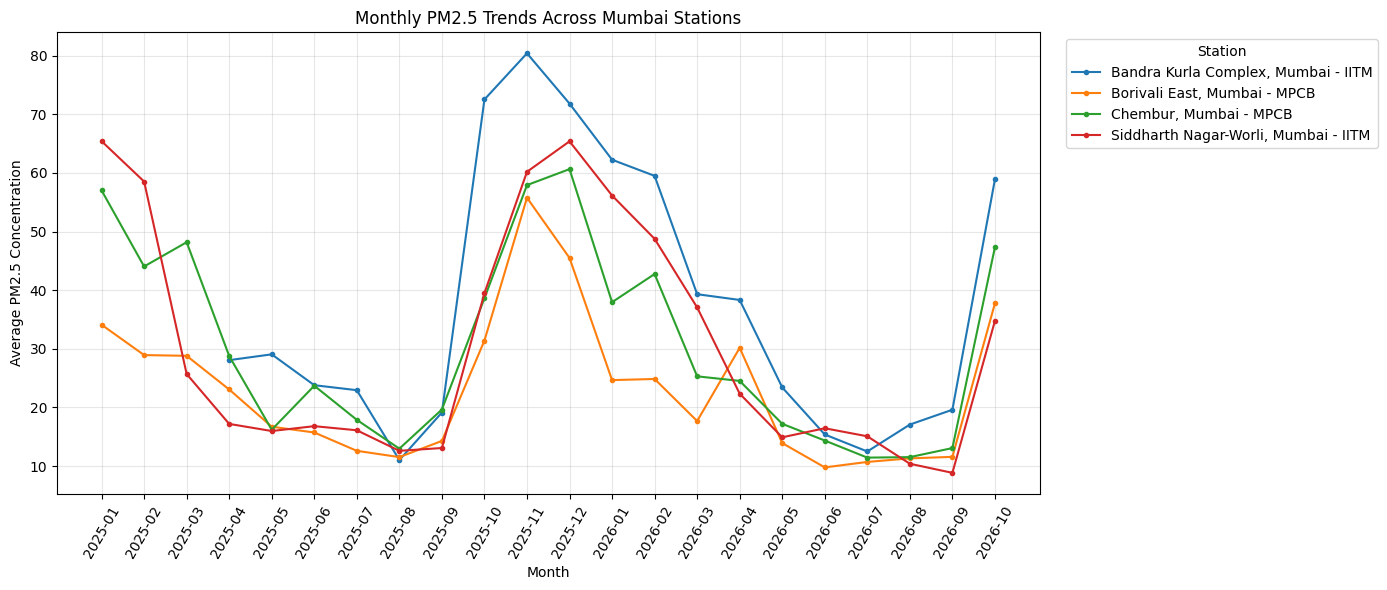

Monthly trend data saved successfully!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Prepare dates
eda_data["From Date"] = pd.to_datetime(
    eda_data["From Date"], errors="coerce"
)

eda_data["Month"] = eda_data["From Date"].dt.to_period("M")

# Calculate monthly average PM2.5 for every station
monthly_pm25 = (
    eda_data.groupby(["Month", "Station"])["PM2.5"]
    .mean()
    .unstack("Station")
)

# Show the data
print(monthly_pm25.round(2).to_string())

# Draw a separate line for every station
fig, ax = plt.subplots(figsize=(14, 6))

for station in monthly_pm25.columns:
    ax.plot(
        monthly_pm25.index.astype(str),
        monthly_pm25[station],
        marker="o",
        markersize=3,
        label=station
    )

ax.set_title("Monthly PM2.5 Trends Across Mumbai Stations")
ax.set_xlabel("Month")
ax.set_ylabel("Average PM2.5 Concentration")
ax.tick_params(axis="x", rotation=60)
ax.legend(title="Station", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

monthly_pm25.to_csv("/content/monthly_pm25_trends.csv")

print("Monthly trend data saved successfully!")

Yearly average PM2.5:
Year                                   2025   2026
Station                                           
Bandra Kurla Complex, Mumbai - IITM   34.53  32.64
Borivali East, Mumbai - MPCB          25.98  20.34
Chembur, Mumbai - MPCB                35.38  23.78
Siddharth Nagar-Worli, Mumbai - IITM  32.23  25.82


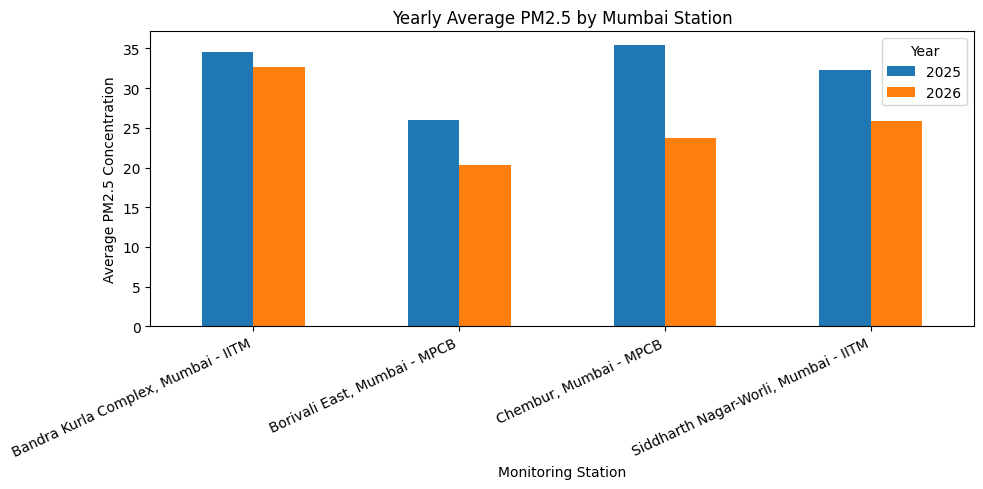

Yearly comparison saved successfully!


In [ ]:
import matplotlib.pyplot as plt

# Extract year from the date
eda_data["Year"] = eda_data["From Date"].dt.year

# Calculate yearly average PM2.5 for each station
yearly_pm25 = eda_data.pivot_table(
    index="Station",
    columns="Year",
    values="PM2.5",
    aggfunc="mean"
)

print("Yearly average PM2.5:")
print(yearly_pm25.round(2))

# Plot comparison
yearly_pm25.plot(kind="bar", figsize=(10, 5))

plt.title("Yearly Average PM2.5 by Mumbai Station")
plt.xlabel("Monitoring Station")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

# Save results
yearly_pm25.to_csv("/content/yearly_pm25_comparison.csv")

print("Yearly comparison saved successfully!")

In [ ]:
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NH3", "SO2", "CO"]

# Get the highest readings for each pollutant
for pollutant in pollutants:
    print(f"\n--- Highest 5 readings: {pollutant} ---")

    highest = eda_data.nlargest(5, pollutant)[
        ["From Date", "Station", pollutant]
    ]

    print(highest.to_string(index=False))


--- Highest 5 readings: PM2.5 ---
          From Date                             Station  PM2.5
2026-08-04 19:00:00              Chembur, Mumbai - MPCB 771.39
2025-10-21 01:00:00 Bandra Kurla Complex, Mumbai - IITM 555.79
2025-10-21 02:00:00 Bandra Kurla Complex, Mumbai - IITM 537.11
2025-07-29 01:00:00 Bandra Kurla Complex, Mumbai - IITM 443.96
2025-10-21 00:00:00 Bandra Kurla Complex, Mumbai - IITM 437.90

--- Highest 5 readings: PM10 ---
          From Date                             Station   PM10
2025-10-21 01:00:00 Bandra Kurla Complex, Mumbai - IITM 699.41
2025-10-21 02:00:00 Bandra Kurla Complex, Mumbai - IITM 646.20
2025-12-11 08:00:00        Borivali East, Mumbai - MPCB 615.00
2025-07-29 03:00:00 Bandra Kurla Complex, Mumbai - IITM 602.02
2025-05-25 11:00:00        Borivali East, Mumbai - MPCB 599.94

--- Highest 5 readings: NO ---
          From Date                             Station     NO
2026-03-23 07:00:00 Bandra Kurla Complex, Mumbai - IITM 446.22
2026-03-23 02:00:

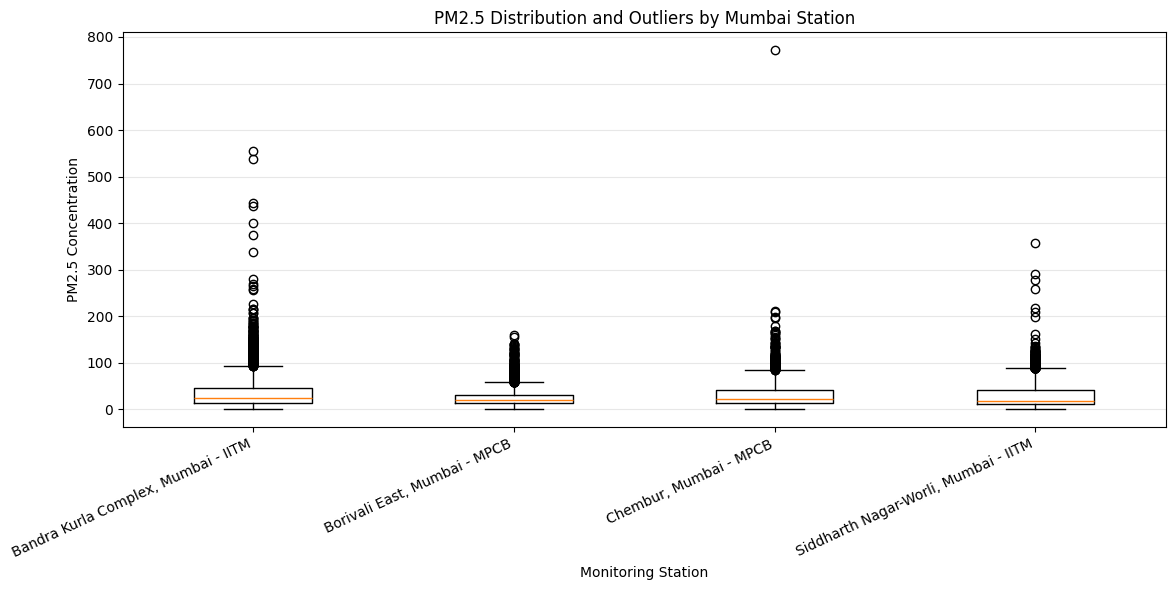

In [ ]:
import matplotlib.pyplot as plt

stations = eda_data["Station"].unique()

data_to_plot = [
    eda_data.loc[
        eda_data["Station"] == station, "PM2.5"
    ].dropna()
    for station in stations
]

plt.figure(figsize=(12, 6))
plt.boxplot(data_to_plot, tick_labels=stations, showfliers=True)

plt.title("PM2.5 Distribution and Outliers by Mumbai Station")
plt.xlabel("Monitoring Station")
plt.ylabel("PM2.5 Concentration")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

outlier_reports = []

for station in eda_data["Station"].unique():
    values = eda_data.loc[
        eda_data["Station"] == station, "PM2.5"
    ].dropna()

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    station_data = eda_data[
        (eda_data["Station"] == station)
        & (
            (eda_data["PM2.5"] < lower_bound)
            | (eda_data["PM2.5"] > upper_bound)
        )
    ][["From Date", "Station", "PM2.5"]].copy()

    outlier_reports.append(station_data)

outliers = pd.concat(outlier_reports, ignore_index=True)

outliers.to_csv(
    "/content/pm25_potential_outliers.csv",
    index=False
)

print("Potential PM2.5 outliers:", len(outliers))
print(outliers.head(10).to_string(index=False))
print("Saved: pm25_potential_outliers.csv")

Potential PM2.5 outliers: 1281
          From Date                             Station  PM2.5
2025-05-13 23:00:00 Bandra Kurla Complex, Mumbai - IITM 118.77
2025-07-29 01:00:00 Bandra Kurla Complex, Mumbai - IITM 443.96
2025-07-29 02:00:00 Bandra Kurla Complex, Mumbai - IITM 280.01
2025-07-29 03:00:00 Bandra Kurla Complex, Mumbai - IITM 146.69
2025-10-10 23:00:00 Bandra Kurla Complex, Mumbai - IITM 104.24
2025-10-11 00:00:00 Bandra Kurla Complex, Mumbai - IITM 101.40
2025-10-11 01:00:00 Bandra Kurla Complex, Mumbai - IITM  96.80
2025-10-11 02:00:00 Bandra Kurla Complex, Mumbai - IITM 102.94
2025-10-11 10:00:00 Bandra Kurla Complex, Mumbai - IITM 101.87
2025-10-11 22:00:00 Bandra Kurla Complex, Mumbai - IITM  95.54
Saved: pm25_potential_outliers.csv


In [ ]:
# Count valid PM2.5 readings at each station
valid_counts = (
    eda_data.groupby("Station")["PM2.5"]
    .count()
    .rename("Valid readings")
)

# Count potential outliers at each station
outlier_counts = (
    outliers.groupby("Station")
    .size()
    .rename("Potential outliers")
)

# Combine the counts
outlier_summary = pd.concat(
    [valid_counts, outlier_counts], axis=1
).fillna(0)

outlier_summary["Potential outliers"] = (
    outlier_summary["Potential outliers"].astype(int)
)

outlier_summary["Outlier percentage"] = (
    outlier_summary["Potential outliers"]
    / outlier_summary["Valid readings"] * 100
).round(2)

print(outlier_summary)

# Save the summary
outlier_summary.to_csv(
    "/content/pm25_outlier_summary.csv"
)

print("\nSaved: pm25_outlier_summary.csv")

                                      Valid readings  Potential outliers  \
Station                                                                    
Bandra Kurla Complex, Mumbai - IITM             9991                 308   
Borivali East, Mumbai - MPCB                   11729                 376   
Chembur, Mumbai - MPCB                         14862                 297   
Siddharth Nagar-Worli, Mumbai - IITM           13496                 300   

                                      Outlier percentage  
Station                                                   
Bandra Kurla Complex, Mumbai - IITM                 3.08  
Borivali East, Mumbai - MPCB                        3.21  
Chembur, Mumbai - MPCB                              2.00  
Siddharth Nagar-Worli, Mumbai - IITM                2.22  

Saved: pm25_outlier_summary.csv


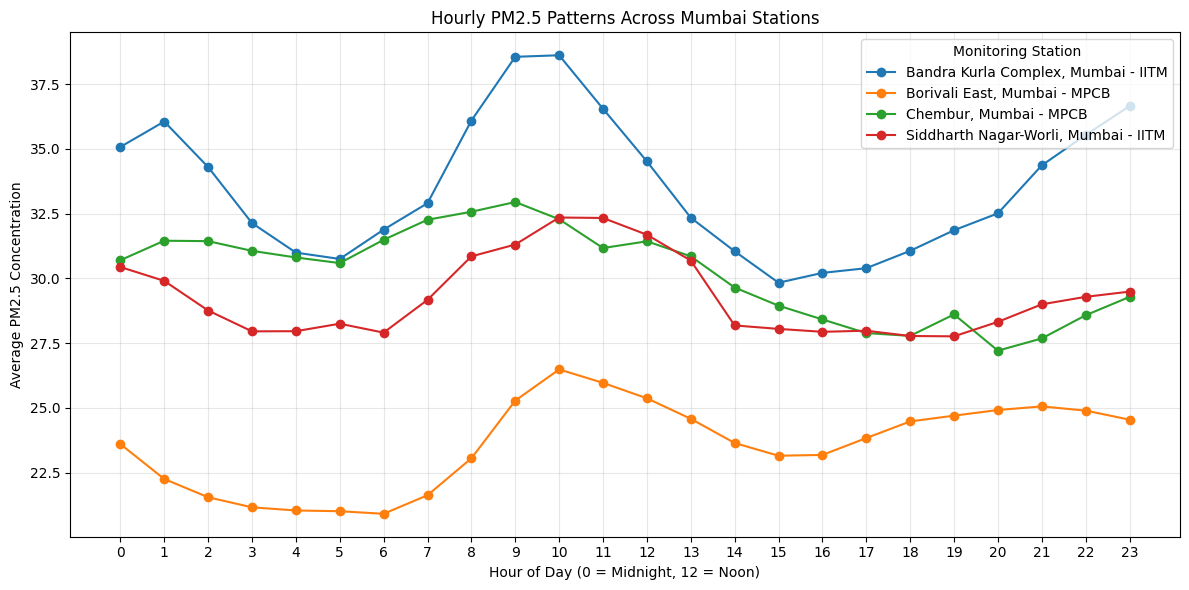

Hourly analysis saved successfully!


In [ ]:
# Extract hour from timestamp
eda_data["Hour"] = eda_data["From Date"].dt.hour

# Calculate average PM2.5 for each hour and station
hourly_pm25 = eda_data.pivot_table(
    index="Hour",
    columns="Station",
    values="PM2.5",
    aggfunc="mean"
)

# Plot hourly patterns
hourly_pm25.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Hourly PM2.5 Patterns Across Mumbai Stations")
plt.xlabel("Hour of Day (0 = Midnight, 12 = Noon)")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.legend(title="Monitoring Station")
plt.tight_layout()
plt.show()

# Save results
hourly_pm25.to_csv("/content/hourly_pm25_patterns.csv")

print("Hourly analysis saved successfully!")

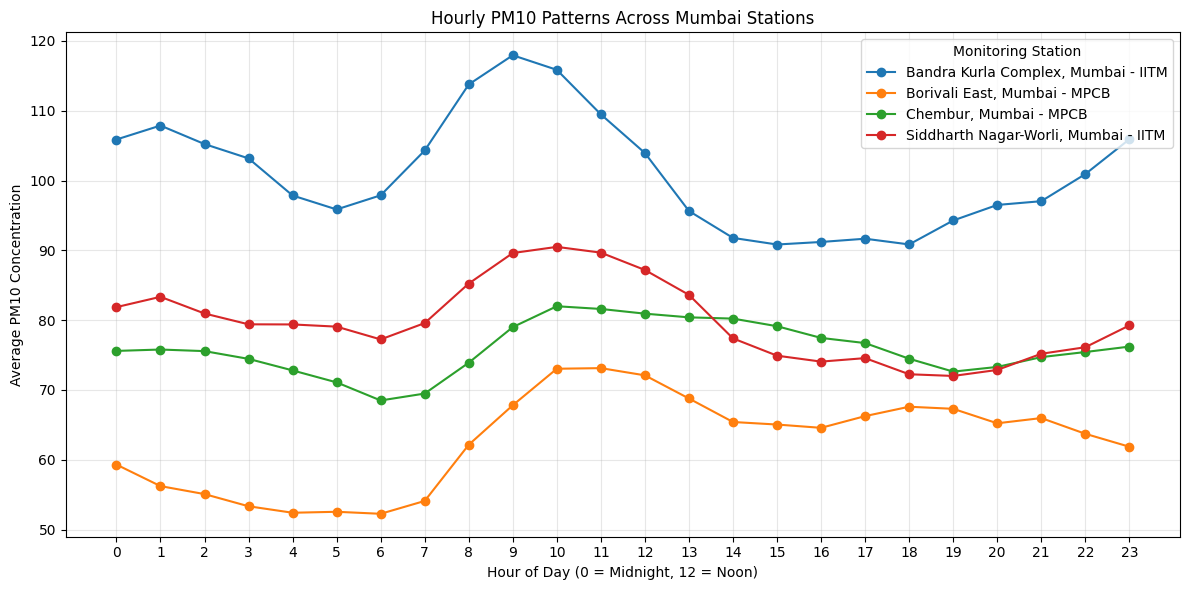

Hourly PM10 analysis saved successfully!


In [ ]:
# Calculate average PM10 for each hour and station
hourly_pm10 = eda_data.pivot_table(
    index="Hour",
    columns="Station",
    values="PM10",
    aggfunc="mean"
)

# Plot hourly PM10 patterns
hourly_pm10.plot(
    figsize=(12, 6),
    marker="o"
)

plt.title("Hourly PM10 Patterns Across Mumbai Stations")
plt.xlabel("Hour of Day (0 = Midnight, 12 = Noon)")
plt.ylabel("Average PM10 Concentration")
plt.xticks(range(0, 24))
plt.grid(True, alpha=0.3)
plt.legend(title="Monitoring Station")
plt.tight_layout()
plt.show()

# Save results
hourly_pm10.to_csv("/content/hourly_pm10_patterns.csv")

print("Hourly PM10 analysis saved successfully!")

In [ ]:
# Keep the original date and pollutant columns
final_columns = [
    "From Date",
    "To Date",
    "Station",
    "PM2.5",
    "PM10",
    "NO",
    "NO2",
    "NH3",
    "SO2",
    "CO"
]

# Create the final analysis dataset
final_eda_data = eda_data[final_columns].copy()

# Save as CSV
final_eda_data.to_csv(
    "/content/citypulse_cleaned_data.csv",
    index=False
)

print("Dataset shape:", final_eda_data.shape)
print("Saved: citypulse_cleaned_data.csv")
print(final_eda_data.head())

Dataset shape: (53187, 10)
Saved: citypulse_cleaned_data.csv
               From Date             To Date  \
2321 2025-04-07 17:00:00 2025-04-07 18:00:00   
2322 2025-04-07 18:00:00 2025-04-07 19:00:00   
2323 2025-04-07 19:00:00 2025-04-07 20:00:00   
2324 2025-04-07 20:00:00 2025-04-07 21:00:00   
2325 2025-04-07 21:00:00 2025-04-07 22:00:00   

                                  Station  PM2.5    PM10     NO    NO2    NH3  \
2321  Bandra Kurla Complex, Mumbai - IITM  60.88  120.89  26.63  96.21   6.58   
2322  Bandra Kurla Complex, Mumbai - IITM  62.61  138.53  26.56  95.40   7.31   
2323  Bandra Kurla Complex, Mumbai - IITM  62.48  159.74  38.99  85.61   9.81   
2324  Bandra Kurla Complex, Mumbai - IITM  69.23  159.85  36.36  80.67  10.51   
2325  Bandra Kurla Complex, Mumbai - IITM  73.04  148.13  19.56  68.27  12.42   

       SO2    CO  
2321  3.57  0.88  
2322  3.85  1.16  
2323  3.18  1.16  
2324  2.99  0.95  
2325  2.99  0.66  


In [ ]:
pollutants = ["PM2.5", "PM10", "NO", "NO2", "NH3", "SO2", "CO"]

# Calculate summary statistics by station
summary_report = (
    final_eda_data.groupby("Station")[pollutants]
    .agg(["mean", "median", "min", "max", "count"])
    .round(2)
)

# Save the report
summary_report.to_csv("/content/citypulse_station_summary.csv")

print("Station summary report created successfully!")
print(summary_report)

Station summary report created successfully!
                                      PM2.5                              \
                                       mean median   min     max  count   
Station                                                                   
Bandra Kurla Complex, Mumbai - IITM   33.50  23.64  0.05  555.79   9991   
Borivali East, Mumbai - MPCB          23.61  19.36  0.67  160.40  11729   
Chembur, Mumbai - MPCB                30.21  22.71  0.04  771.39  14862   
Siddharth Nagar-Worli, Mumbai - IITM  29.30  18.50  0.07  357.79  13496   

                                        PM10                              ...  \
                                        mean median   min     max  count  ...   
Station                                                                   ...   
Bandra Kurla Complex, Mumbai - IITM   101.06  83.64  0.06  699.41  10149  ...   
Borivali East, Mumbai - MPCB           62.76  53.55  1.75  615.00  10464  ...   
Chembur, Mumbai - MPCB  

In [ ]:
from google.colab import files

files.download("/content/citypulse_cleaned_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("/content/citypulse_station_summary.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>